<a href="https://colab.research.google.com/github/gmauricio-toledo/math-ML/blob/main/Notebooks/21-Autoencoders-Detecci%C3%B3n_de_anomalias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1>Autoencoders, detección de anomalias y estrategias de balanceo



<h3>Descripción del dataset</h3>
Este dataset contiene 284,807 transacciones con tarjetas de crédito, de las cuales solo 492 (0.172%) son fraudulentas, lo que lo convierte en un caso extremadamente desbalanceado. Las 30 features disponibles son el resultado de una transformación mediante PCA (Análisis de Componentes Principales) para preservar la confidencialidad de los datos. Las únicas columnas sin transformar son Time (segundos transcurridos desde la primera transacción) y Amount (monto de la transacción).

<h3>Problema a Resolver</h3>
El objetivo es clasificar transacciones fraudulentas con alta precisión, minimizando los falsos negativos (transacciones fraudulentas no detectadas) sin afectar demasiado los falsos positivos (transacciones legítimas marcadas como fraudulentas).

<h3>Dificultades Principales</h3>

* Desbalance extremo (fraudes ≈ 0.17% del total).
* Features anonimizadas (no interpretables directamente).
* Alto costo de error:
 * Falsos negativos → Pérdidas económicas.
 * Falsos positivos → Mala experiencia del cliente.



**Información del dataset**

Los conjuntos de datos contienen transacciones realizadas con tarjetas de crédito en septiembre de 2013 por titulares de tarjetas europeos. Este conjunto de datos presenta transacciones que ocurrieron en dos días, donde tenemos 492 fraudes de 284,807 transacciones. El conjunto de datos está altamente desequilibrado, la clase positiva (fraudes) representa el 0.172% de todas las transacciones.

Contiene solo variables de entrada numéricas que son el resultado de una transformación PCA. Debido a cuestiones de confidencialidad, no se pueden obtener las características originales y más información sobre los datos. Las características $V_1$, $V_2$, ..., $V_{28}$ son los componentes principales obtenidos con PCA, las únicas características que no se han transformado con PCA son 'Tiempo' y 'Cantidad'. La función 'Tiempo' contiene los segundos transcurridos entre cada transacción y la primera transacción en el conjunto de datos. La característica 'Cantidad' es la Cantidad de la transacción. La característica 'Clase' es la variable de respuesta y toma el valor 1 en caso de fraude y 0 en caso contrario.


Recordemos las buenas prácticas del Machine Learning: https://scikit-learn.org/stable/common_pitfalls.html

In [101]:
import numpy as np
import matplotlib.pyplot as plt

Descargamos el dataset

In [102]:
!gdown 1k0cJMf8bEoi2esrcbwr7gI9rXmBiTlfG

Downloading...
From (original): https://drive.google.com/uc?id=1k0cJMf8bEoi2esrcbwr7gI9rXmBiTlfG
From (redirected): https://drive.google.com/uc?id=1k0cJMf8bEoi2esrcbwr7gI9rXmBiTlfG&confirm=t&uuid=e07c87c4-8570-4b3f-955e-d87c0ce3dcb9
To: /content/creditcard.zip
100% 66.4M/66.4M [00:00<00:00, 122MB/s] 


Extraer el archivo zip

In [103]:
import numpy as np
from zipfile import ZipFile
import pandas as pd

archivo = "creditcard.zip"

print('Extrayendo contenido...')
with ZipFile(archivo, 'r') as Zip:
    Zip.extractall()
    print('Extracción finalizada.')

credito_df = pd.read_csv("creditcard.csv")

Extrayendo contenido...
Extracción finalizada.


## Análisis Exploratorio

Las 30 features disponibles son el resultado de una transformación mediante PCA para preservar la confidencialidad de los datos. Las únicas columnas sin transformar son Time (segundos transcurridos desde la primera transacción) y Amount (monto de la transacción).

<center>
<p><img src="https://drive.google.com/uc?id=1gURkWL4aU4ogu6YxbX7LzaIZOWbkoVj9" width="300" /></p>
</center>

Forma del dataset:

In [104]:
print(f"Tamaño del dataset: {credito_df.shape}")
credito_df.head()

Tamaño del dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Exploremos los rangos de las variables

In [105]:
credito_df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


De la tabla estadística anterior podemos destacar tres observaciones clave para el preprocesamiento:

* **Escalas heterogéneas:** Mientras que las componentes principales $V_1, \dots, V_{28}$ están centradas alrededor de $0$ (con desviaciones estándar entre $0.33$ y $1.96$), las variables sin transformar tienen magnitudes muy distintas: `Time` abarca de $0$ a $172,792$ segundos ($\approx 48$ horas) y `Amount` alcanza un máximo de $25,691.16$.
* **Fuerte asimetría en `Amount`:** La media es de $88.35$, pero la mediana (percentil 50%) es de apenas $22.00$, lo que indica una distribución fuertemente sesgada a la derecha con presencia de valores atípicos (*outliers*) elevados.
* **Confirmación del desbalance:** La media de la columna `Class` es $0.001727$, lo que confirma que solo el $0.172\%$ de las observaciones corresponden a la clase positiva (fraude).

<Figure size 640x480 with 0 Axes>

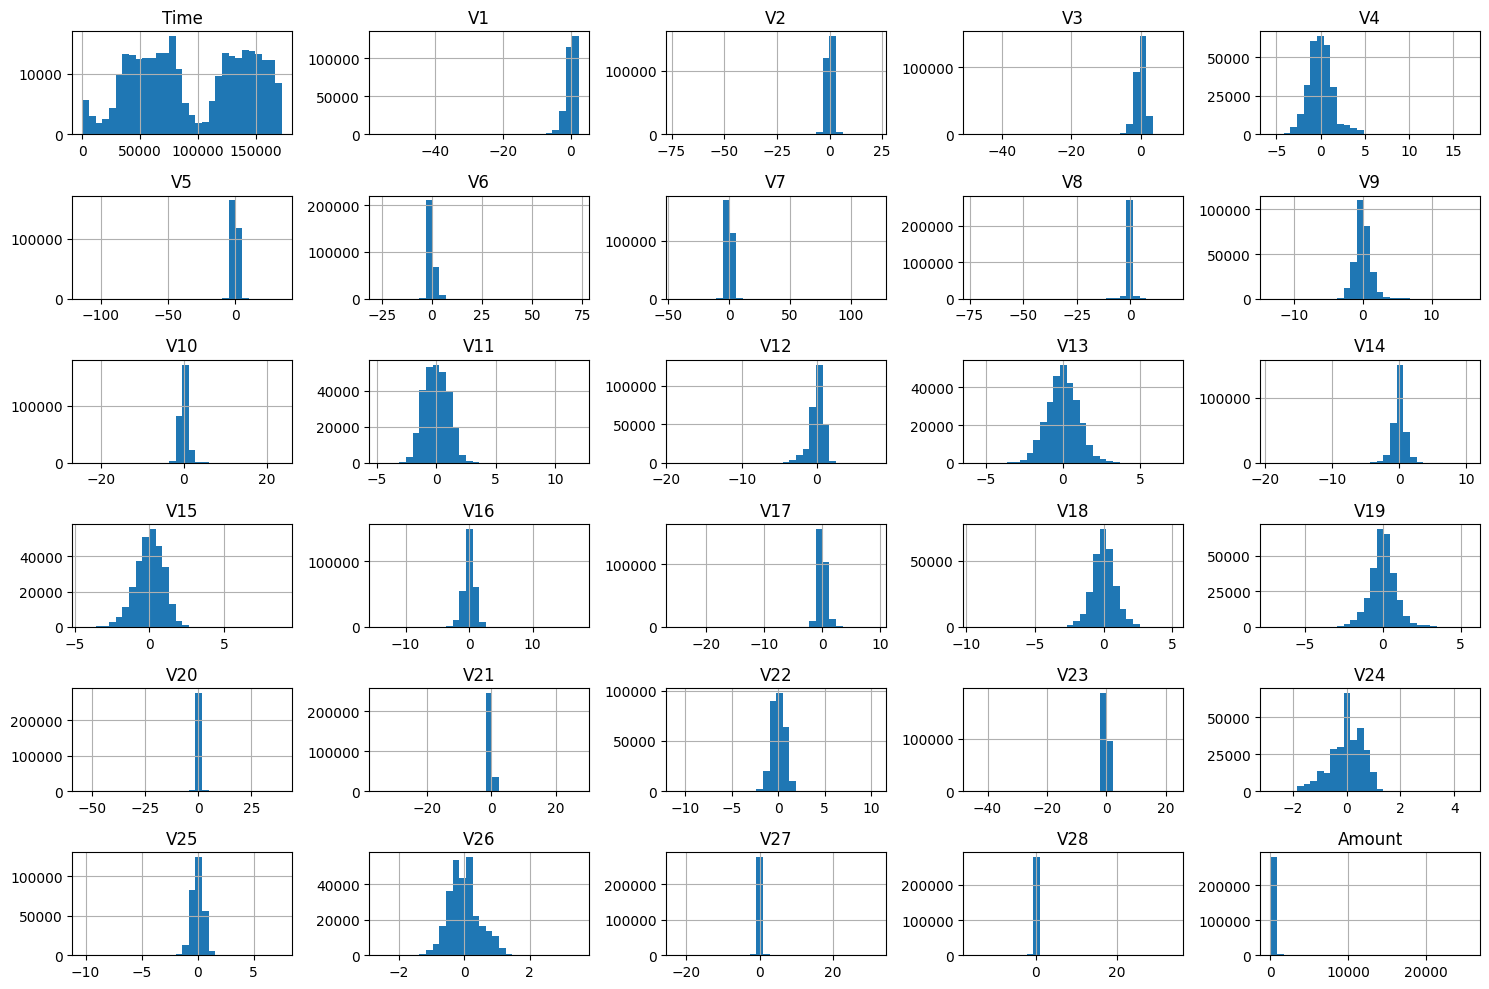

In [106]:
from seaborn import histplot

cols_to_plot = credito_df.columns.to_list()[:-1]

plt.figure()
credito_df[cols_to_plot].hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

Al inspeccionar las distribuciones de todas las *features*:

* **Comportamiento temporal (`Time`):** Se observa una distribución bimodal con dos ciclos claros correspondientes a los dos días de registro, mostrando caídas pronunciadas en la actividad durante las horas de la madrugada.
* **Componentes PCA ($V_1$ a $V_{28}$):** La mayoría presenta distribuciones aproximadamente simétricas alrededor de cero, aunque con colas pesadas y curtosis pronunciada en varias componentes, reflejo de transacciones atípicas.
* **Necesidad de escalamiento:** Dado que algoritmos basados en gradiente o distancias (como Regresión Logística o SVM) son sensibles a la escala, será indispensable estandarizar o escalar `Time` y `Amount` antes de entrenar.

Podemos notar algunos patrones en los datos:

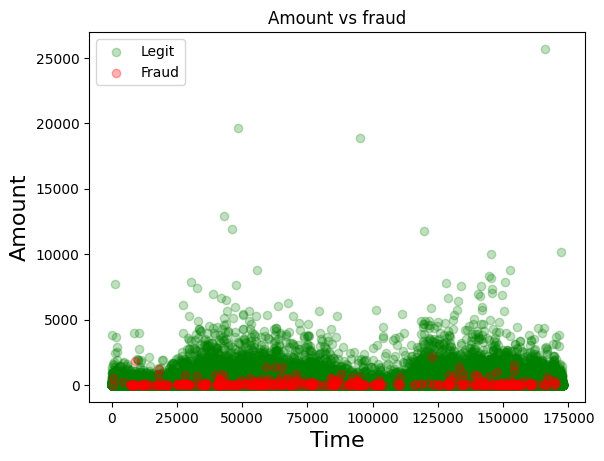

In [107]:
import matplotlib.pyplot as plt

plt.figure()

# Graficamos los que no son fraude
time_amount = credito_df[credito_df['Class'] == 0][['Time','Amount']].values
plt.scatter(time_amount[:,0], time_amount[:,1],
            c='green',alpha=0.25,label='Legit')
# Graficamos los que sí son fraude
time_amount = credito_df[credito_df['Class'] == 1][['Time','Amount']].values
plt.scatter(time_amount[:,0], time_amount[:,1],
            c='red',label='Fraud',alpha=0.3)
plt.legend(loc='best')
plt.title('Amount vs fraud')
plt.xlabel('Time', fontsize=16)
plt.ylabel('Amount', fontsize=16)
plt.show()

En la gráfica de dispersión anterior observamos dos patrones relevantes:

1. **Distribución en el tiempo:** Los fraudes (puntos rojos) ocurren de manera relativamente uniforme a lo largo de las 48 horas, incluso en los periodos de baja actividad transaccional.
2. **Montos de fraude:** La gran mayoría de las transacciones fraudulentas se concentran en montos bajos o moderados, sin alcanzar los valores extremos de las transacciones legítimas.

Antes de pasar al modelado, verifiquemos que no existan valores faltantes y cuantifiquemos exactamente el desbalance de la variable objetivo `Class`:

Veamos la distribución de clases y el ratio, la razón entre la clase positiva y el total

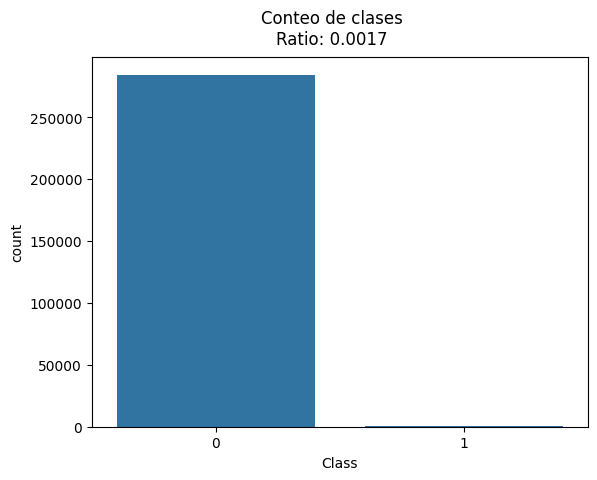

In [108]:
import seaborn as sns

ratio = credito_df[credito_df['Class'] == 1].shape[0]/credito_df.shape[0]

plt.figure()
sns.countplot(x = "Class", data = credito_df)
plt.suptitle(f"Conteo de clases\nRatio: {round(ratio,4)}")
plt.show()

In [109]:
num_frauds = credito_df[credito_df["Class"]==1].shape[0]
num_legits = credito_df[credito_df["Class"]==0].shape[0]

total = credito_df.shape[0]
pf = (num_frauds / total)*100
pn = (num_legits / total)*100

print(f"Hay {num_legits} transacciones normales (clase 0)")
print(f"Hay {num_frauds} transacciones fraudulentas (clase 1)")
print(f"Porcentaje clase 0: {np.round(pn,2)}%")
print(f"Porcentaje clase 1: {np.round(pf,2)}%")

Hay 284315 transacciones normales (clase 0)
Hay 492 transacciones fraudulentas (clase 1)
Porcentaje clase 0: 99.83%
Porcentaje clase 1: 0.17%


# 1. Clasificación


<h3>Técnicas Recomendadas</h3>

1. Manejo de desbalance:
 * Undersampling (reducir la clase mayoritaria).
 * Oversampling (SMOTE, ADASYN) para generar fraudes sintéticos.
 * Pesado de clases (class_weight en modelos).

2. Selección de métricas:
 * Precision-Recall > Accuracy (por el desbalance).
 * AUC-ROC y F1-Score.

3. Modelos adecuados:
 * Regresión Logística (con regularización L1/L2).
 * Random Forest / XGBoost (manejo automático de desbalance).
 * Autoencoders (pendiente...)

In [110]:
from sklearn.model_selection import train_test_split

# Semillas globales para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Variables predictoras y objetivo en formato 1D (N,)
X = credito_df.drop(columns=['Class'])
y = credito_df['Class'].to_numpy().ravel()

# Partición única estratificada: 70% Train, 15% Validación, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape[0]} filas ({y_train.sum()} fraudes)")
print(f"Val:   {X_val.shape[0]} filas ({y_val.sum()} fraudes)")
print(f"Test:  {X_test.shape[0]} filas ({y_test.sum()} fraudes)")

Train: 199364 filas (344 fraudes)
Val:   42721 filas (74 fraudes)
Test:  42722 filas (74 fraudes)


Definamos una función para mostrar las evaluaciones y evitar reescribir tanto código:

In [111]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

def show_metrics(
                    y_train,
                    y_test,
                    y_pred_train,
                    y_pred_test,
                    y_score_train=None,
                    y_score_test=None,
                    model_name="Modelo"
                ):
    y_train = np.asarray(y_train).ravel()
    y_test = np.asarray(y_test).ravel()
    y_pred_train = np.asarray(y_pred_train).ravel()
    y_pred_test = np.asarray(y_pred_test).ravel()

    sep = "\n" + 30 * "-" + "\n"

    # 1. Métrica única común (AUC-PR): requiere puntajes continuos (probabilidades o MSE)
    auc_pr_train, auc_pr_test = None, None
    if y_score_train is not None and y_score_test is not None:
        auc_pr_train = average_precision_score(y_train, y_score_train)
        auc_pr_test = average_precision_score(y_test, y_score_test)
        print(f"AUC-PR train:    {auc_pr_train:.4f}")
        print(f"AUC-PR test:     {auc_pr_test:.4f}", end=sep)

    # 2. Métricas discretas (dependientes del umbral)
    f1_tr = f1_score(y_train, y_pred_train, zero_division=0)
    f1_te = f1_score(y_test, y_pred_test, zero_division=0)
    prec_te = precision_score(y_test, y_pred_test, zero_division=0)
    rec_te = recall_score(y_test, y_pred_test, zero_division=0)

    print(f"F1-score train:  {f1_tr:.4f}")
    print(f"F1-score test:   {f1_te:.4f}")
    print(f"Precision test:  {prec_te:.4f}")
    print(f"Recall test:     {rec_te:.4f}", end=sep)

    print(f"Accuracy train:  {accuracy_score(y_train, y_pred_train):.4f}")
    print(f"Accuracy test:   {accuracy_score(y_test, y_pred_test):.4f}", end=sep)

    # 3. Gráficas: Matriz de confusión y Curva Precision-Recall
    if y_score_test is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

        sns.heatmap(
            confusion_matrix(y_test, y_pred_test),
            annot=True, fmt="d", cmap="Blues", ax=axes[0]
        )
        axes[0].set_title(f"Confusion Matrix - {model_name}")
        axes[0].set_ylabel("True class")
        axes[0].set_xlabel("Predicted class")

        PrecisionRecallDisplay.from_predictions(
            y_test, y_score_test, name=model_name, ax=axes[1]
        )
        axes[1].set_title(f"Precision-Recall Curve (AUC-PR = {auc_pr_test:.4f})")
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
    else:
        cm = confusion_matrix(y_test, y_pred_test)
        plt.figure()
        sns.heatmap(cm, annot=True, fmt="d")
        plt.title(f"Confusion matrix - {model_name}")
        plt.ylabel("True class")
        plt.xlabel("Predicted class")
        plt.show()

    return {
        "Modelo": model_name,
        "AUC-PR (test)": auc_pr_test,
        "F1 (test)": f1_te,
        "Precision (test)": prec_te,
        "Recall (test)": rec_te,
    }

In [112]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

## Modelo Baseline

🔵 ¿Qué pasa si entrenamos así el modelo?

En este primer modelo no incluimos ningún preprocesamiento ni atendemos al desbalanceo de clases. El proposito es tener un baseline e ilustrar las dificultades de este tipo de datasets.

AUC-PR train:    0.0017
AUC-PR test:     0.0017
------------------------------
F1-score train:  0.0000
F1-score test:   0.0000
Precision test:  0.0000
Recall test:     0.0000
------------------------------
Accuracy train:  0.9983
Accuracy test:   0.9983
------------------------------


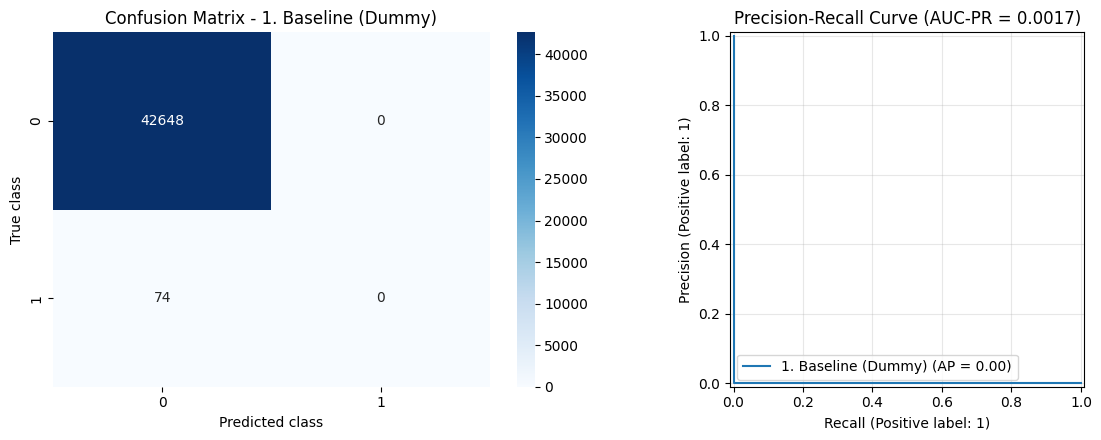

In [113]:
# 1. Modelo Baseline (siempre predice clase 0)
baseline_clf = DummyClassifier(strategy="most_frequent")
baseline_clf.fit(X_train, y_train)

res_baseline = show_metrics(
    y_train, y_test,
    y_pred_train=baseline_clf.predict(X_train),
    y_pred_test=baseline_clf.predict(X_test),
    y_score_train=baseline_clf.predict_proba(X_train)[:, 1],
    y_score_test=baseline_clf.predict_proba(X_test)[:, 1],
    model_name="1. Baseline (Dummy)"
)

## Modelo con Reescalamiento

AUC-PR train:    0.7904
AUC-PR test:     0.7499
------------------------------
F1-score train:  0.7441
F1-score test:   0.7402
Precision test:  0.8868
Recall test:     0.6351
------------------------------
Accuracy train:  0.9992
Accuracy test:   0.9992
------------------------------


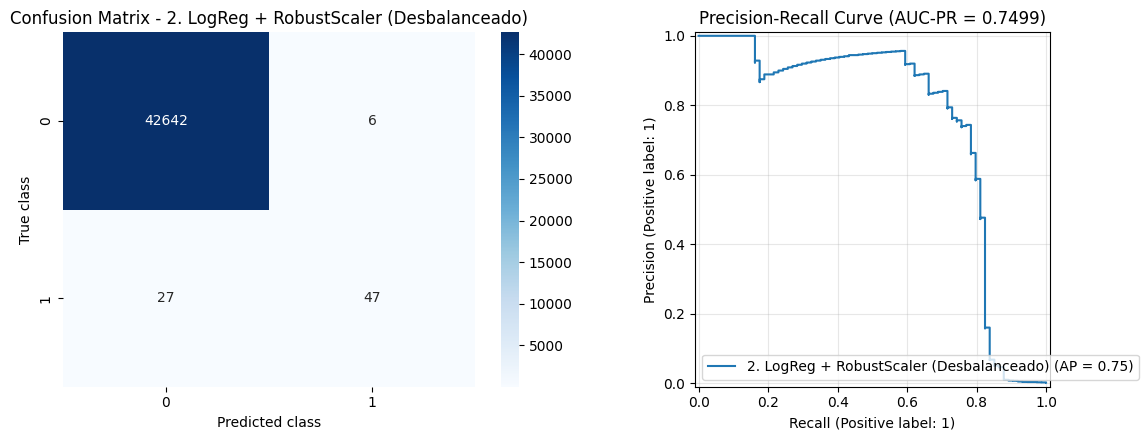

In [114]:
# 2. Modelo con reescalamiento, sin atender el desbalance
pipe_scaled = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
pipe_scaled.fit(X_train, y_train)

res_scaled = show_metrics(
    y_train, y_test,
    y_pred_train=pipe_scaled.predict(X_train),
    y_pred_test=pipe_scaled.predict(X_test),
    y_score_train=pipe_scaled.predict_proba(X_train)[:, 1],
    y_score_test=pipe_scaled.predict_proba(X_test)[:, 1],
    model_name="2. LogReg + RobustScaler (Desbalanceado)"
)

## Modelo Desbalanceo

En esta sección abordaremos el problema del desbalanceo de clases usando varias estrategias:

1. Submuestreo
2. Sobremuestreo
3. SMOTE
4. Combinando estrategias

En todas las estrategias, recordar que es primero la división train/test y luego abordar el desbalanceo en la parte train solamente.


AUC-PR train:    0.7734
AUC-PR test:     0.7950
------------------------------
F1-score train:  0.2249
F1-score test:   0.2165
Precision test:  0.1240
Recall test:     0.8514
------------------------------
Accuracy train:  0.9891
Accuracy test:   0.9893
------------------------------


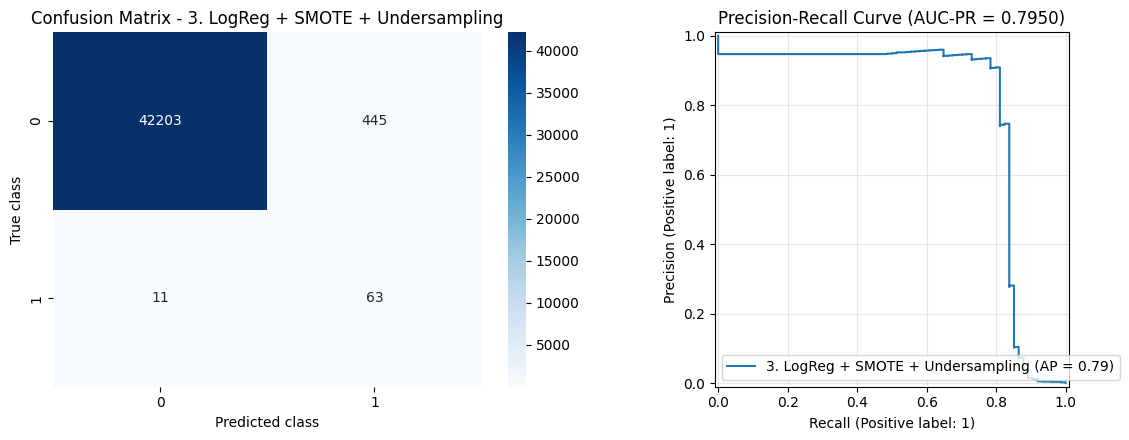

In [115]:
# 3. Modelo con estrategia híbrida: Oversampling (SMOTE) + Undersampling
pipe_resampled = ImbPipeline([
    ("scaler", RobustScaler()),
    ("over", SMOTE(sampling_strategy=0.1, random_state=42)),
    ("under", RandomUnderSampler(sampling_strategy=0.5, random_state=42)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
pipe_resampled.fit(X_train, y_train)

res_resampled = show_metrics(
    y_train, y_test,
    y_pred_train=pipe_resampled.predict(X_train),
    y_pred_test=pipe_resampled.predict(X_test),
    y_score_train=pipe_resampled.predict_proba(X_train)[:, 1],
    y_score_test=pipe_resampled.predict_proba(X_test)[:, 1],
    model_name="3. LogReg + SMOTE + Undersampling"
)

In [116]:
comparativa_df = pd.DataFrame([
    res_baseline,
    res_scaled,
    res_resampled,
    # res_ae
]).sort_values("AUC-PR (test)", ascending=False)

display(comparativa_df)

,Modelo,AUC-PR (test),F1 (test),Precision (test),Recall (test)
2,3. LogReg + SMOTE + Undersampling,0.794960,0.216495,0.124016,0.851351
1,2. LogReg + RobustScaler (Desbalanceado),0.749879,0.740157,0.886792,0.635135
0,1. Baseline (Dummy),0.001732,0.000000,0.000000,0.000000


# 2. Detección de anomalias: Autoencoder

A diferencia de los modelos supervisados anteriores, un **Autoencoder** permite abordar el fraude como un problema de **detección de anomalías** (*one-class learning*):

1. **Entrenamiento exclusivo con clase normal:** Entrenamos la red neuronal únicamente con transacciones legítimas (`Class = 0`). El modelo aprende a comprimir las 30 características en un espacio latente de menor dimensión y a reconstruirlas fielmente.
2. **Error de reconstrucción como puntaje de anomalía:** Dado que el Autoencoder nunca vio ejemplos de fraude durante el entrenamiento, al intentar reconstruir una transacción fraudulenta (`Class = 1`) producirá un error cuadrático medio (**MSE**) significativamente mayor:

$$\text{MSE}(\mathbf{x}, \hat{\mathbf{x}}) = \frac{1}{d} \sum_{i=1}^{d} (x_i - \hat{x}_i)^2$$

3. **Regla de decisión:** Si $\text{MSE}(\mathbf{x}, \hat{\mathbf{x}}) > \tau$, clasificamos la transacción como fraude. Para evitar fuga de datos (*data leakage*), tanto el escalador (`RobustScaler`) como la selección del umbral $\tau$ se calibran sin tocar el conjunto de prueba.

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
            average_precision_score,
            precision_recall_curve,
            classification_report,
            confusion_matrix
        )

# 2. Filtrar únicamente transacciones legítimas para entrenar el Autoencoder
X_train_normal = X_train[y_train == 0]
X_val_normal = X_val[y_val == 0]

In [118]:
# 3. Escalamiento ajustado exclusivamente sobre transacciones legítimas de entrenamiento
scaler = RobustScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)

X_val_normal_scaled = scaler.transform(X_val_normal)
X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

In [128]:
# 4. Arquitectura del Autoencoder (30 -> 20 -> 10 -> 20 -> 30)
input_dim = X_train_normal_scaled.shape[1]

autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(24, activation='elu', activity_regularizer=tf.keras.regularizers.l1(1e-5)),
    layers.Dense(12, activation='elu'),
    layers.Dense(6, activation='elu'),   # Cuello de botella más estrecho
    layers.Dense(12, activation='elu'),
    layers.Dense(24, activation='elu'),
    layers.Dense(input_dim, activation='linear')  # Salida lineal: las features escaladas no están acotadas en [0, 1]
])

autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse')

early_stop = callbacks.EarlyStopping(
                                monitor='val_loss',
                                patience=5,
                                restore_best_weights=True
                            )

In [129]:
history = autoencoder.fit(
    X_train_normal_scaled, X_train_normal_scaled,
    epochs=50,
    batch_size=256,
    validation_data=(X_val_normal_scaled, X_val_normal_scaled),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 1.2638 - val_loss: 0.8811
Epoch 2/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.7320 - val_loss: 0.6594
Epoch 3/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.6223 - val_loss: 0.5986
Epoch 4/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.5936 - val_loss: 0.5760
Epoch 5/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5608 - val_loss: 0.5556
Epoch 6/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5443 - val_loss: 0.5381
Epoch 7/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5276 - val_loss: 0.5229
Epoch 8/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5153 - val_loss: 0.5096
Epoch 9/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5018 - val_loss: 0.4989
Epoch 10/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4935 - val_loss: 0.4912
Epoch 11/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4835 - val_loss: 0.4842
Epoch 12/50
778/778 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step

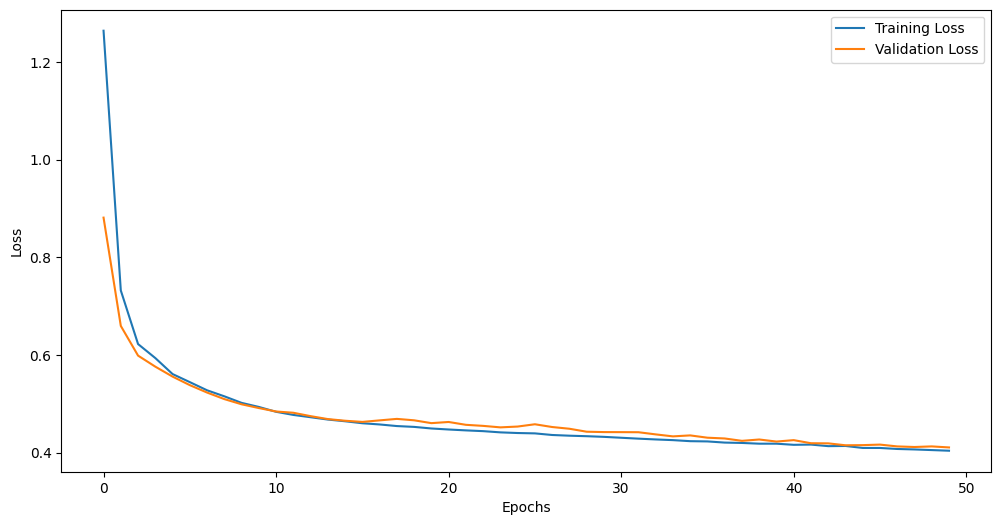

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Función para obtener el error de reconstrucción de un modelo

In [131]:
def calcular_error_reconstruccion(modelo, X_datos):
    reconstrucciones = modelo.predict(X_datos, verbose=0)
    return np.mean(np.square(X_datos - reconstrucciones), axis=1)

Obtener errores de reconstrucción

In [132]:
# 1. Obtener errores de reconstrucción (MSE) en validación y prueba
mse_val = calcular_error_reconstruccion(autoencoder, X_val_scaled)
mse_test = calcular_error_reconstruccion(autoencoder, X_test_scaled)

In [133]:
# 2. Calibrar el umbral óptimo (maximizando F1-Score) usando únicamente el conjunto de validación
precisions_val, recalls_val, thresholds_val = precision_recall_curve(y_val, mse_val)
f1_val = 2 * (precisions_val[:-1] * recalls_val[:-1]) / (precisions_val[:-1] + recalls_val[:-1] + 1e-10)

best_idx = np.argmax(f1_val)
umbral_optimo = thresholds_val[best_idx]

print(f"Umbral de error MSE calibrado en validación: {umbral_optimo:.4f}")

Umbral de error MSE calibrado en validación: 7.5453


AUC-PR train:    0.5674
AUC-PR test:     0.5834
------------------------------
F1-score train:  0.5792
F1-score test:   0.5625
Precision test:  0.6667
Recall test:     0.4865
------------------------------
Accuracy train:  0.9986
Accuracy test:   0.9987
------------------------------


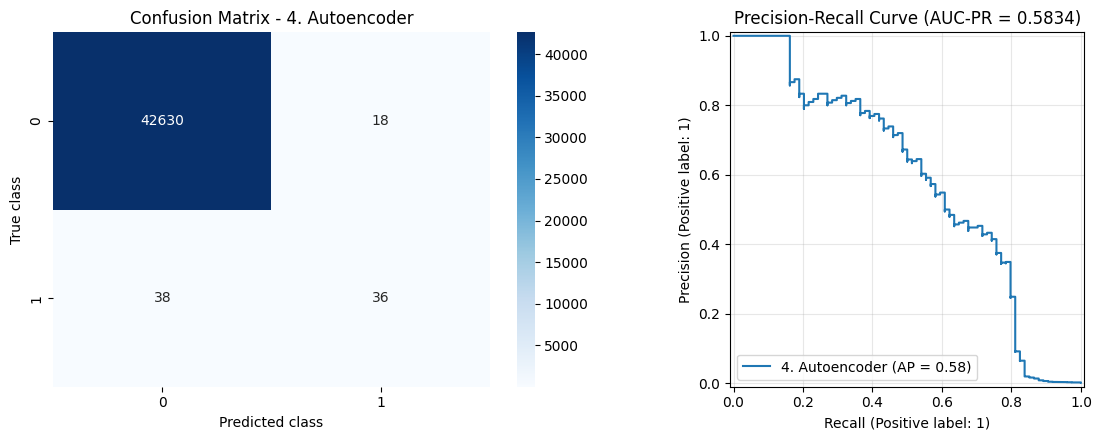

In [134]:
# Calcular el error de reconstrucción (MSE) en train usando el scaler ya ajustado
X_train_scaled = scaler.transform(X_train)
mse_train = calcular_error_reconstruccion(autoencoder, X_train_scaled)

# Predicciones binarias con el umbral calibrado en X_val
y_pred_train_ae = (mse_train > umbral_optimo).astype(int)
y_pred_test_ae = (mse_test > umbral_optimo).astype(int)

# Llamada directa a show_metrics
res_ae = show_metrics(
    y_train,
    y_test,
    y_pred_train=y_pred_train_ae,
    y_pred_test=y_pred_test_ae,
    y_score_train=mse_train,
    y_score_test=mse_test,
    model_name="4. Autoencoder"
)

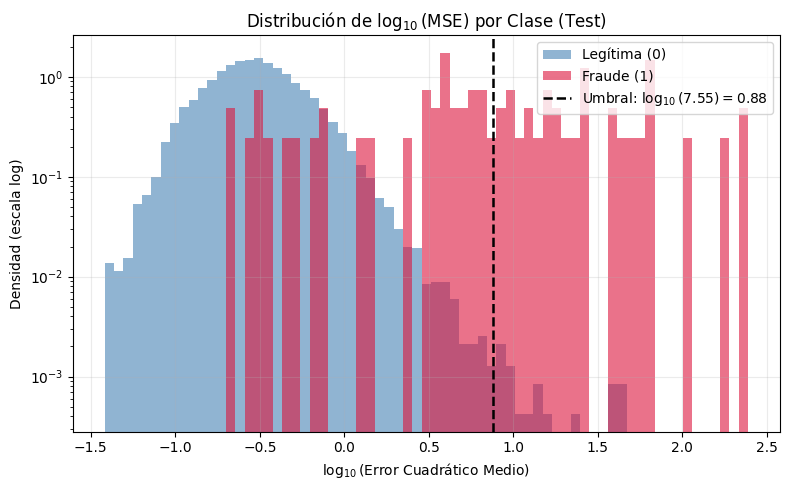

In [141]:
log_mse = np.log10(mse_test + 1e-8)
log_umbral = np.log10(umbral_optimo)
bins_log = np.linspace(log_mse.min(), log_mse.max(), 70)

plt.figure(figsize=(8, 5))

plt.hist(
    log_mse[y_test == 0],
    bins=bins_log, density=True, alpha=0.6, color='steelblue', label='Legítima (0)'
)
plt.hist(
    log_mse[y_test == 1],
    bins=bins_log, density=True, alpha=0.6, color='crimson', label='Fraude (1)'
)
plt.axvline(
    log_umbral, color='black', linestyle='--', linewidth=1.8,
    label=f'Umbral: $\\log_{{10}}({umbral_optimo:.2f}) = {log_umbral:.2f}$'
)

plt.yscale('log')
plt.title('Distribución de $\\log_{10}$(MSE) por Clase (Test)')
plt.xlabel('$\\log_{10}$(Error Cuadrático Medio)')
plt.ylabel('Densidad (escala log)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Observaciones sobre el modelo basado en Autoencoder

* **Separación en el espacio de reconstrucción:** Al observar el histograma de errores, la gran mayoría de las transacciones legítimas se concentran cerca de cero, mientras que los fraudes presentan una cola derecha mucho más extendida debido a que sus combinaciones de componentes $V_1, \dots, V_{28}$ no siguen la variedad (*manifold*) aprendida durante el entrenamiento.
* **Comparación frente a modelos supervisados:** Aunque el Autoencoder no utiliza etiquetas de fraude para ajustar sus pesos, logra detectar una proporción relevante de anomalías. Sin embargo, dado que algunas transacciones legítimas atípicas (montos muy altos o patrones inusuales) también generan errores elevados, los modelos supervisados entrenados con etiquetas (`class_weight` o ensambles) suelen alcanzar un **AUC-PR** superior cuando se dispone de ejemplos etiquetados históricos.

In [136]:
comparativa_df = pd.DataFrame([
    res_baseline,
    res_scaled,
    res_resampled,
    res_ae
]).sort_values("AUC-PR (test)", ascending=False)

display(comparativa_df)

,Modelo,AUC-PR (test),F1 (test),Precision (test),Recall (test)
2,3. LogReg + SMOTE + Undersampling,0.794960,0.216495,0.124016,0.851351
1,2. LogReg + RobustScaler (Desbalanceado),0.749879,0.740157,0.886792,0.635135
3,4. Autoencoder,0.583443,0.562500,0.666667,0.486486
0,1. Baseline (Dummy),0.001732,0.000000,0.000000,0.000000


### Antes de programar: 5 piezas independientes que convergen aquí

En estas notebook aparecieron varios elementos nuevos a la vez. Para no mezclar conceptos, conviene distinguir qué hace cada uno por separado:

1. **La arquitectura (`Autoencoder`):** Es simplemente una red neuronal que comprime los datos a un espacio latente y los reconstruye ($\mathbf{x} \to \mathbf{z} \to \hat{\mathbf{x}}$).
2. **La API funcional de Keras (`Model` vs. `Sequential`):** Es solo una forma más flexible de definir redes conectando capas como funciones (útil si después quieres usar solo la mitad `encoder`), pero la arquitectura matemática es la misma.
3. **El entrenamiento (`EarlyStopping`):** Es un *callback* general de Keras para detener el entrenamiento antes de que la red sobreajuste; sirve para cualquier modelo de Deep Learning.
4. **El enfoque del problema (*Detección de Anomalías*):** En lugar de entrenar un clasificador entre dos clases, entrenamos el Autoencoder **únicamente con transacciones legítimas** y usamos su error de reconstrucción como medida de anomalía.
5. **La evaluación (`AUC-PR`):** Es una métrica de evaluación, usada tipicamente en escenarios de desbalance extremo, necesita tener las predicciones de las probabilidades.